<a href="https://colab.research.google.com/github/alirezakiann/cx-radar/blob/main/01_data_snappfood.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - دریافت دیتاست اسنپ‌فود (بدون Google Drive)
همه‌چیز روی خود Colab اجرا می‌شه. داده هر بار از Kaggle دوباره دانلود می‌شه (چند ثانیه) و کد توی GitHub نگه‌داری می‌شه.

## قدم ۱: ذخیره‌ی توکن Kaggle توی Colab Secrets
توکنی که Kaggle بهت داده رو **توی نوت‌بوک ننویس**. به‌جاش:
1. توی Colab سمت چپ روی آیکون **کلید 🔑 (Secrets)** بزن.
2. `Add new secret` بزن.
3. اسم: `KAGGLE_API_TOKEN` (دقیقاً همین)
4. مقدار: توکنی که از Kaggle گرفتی (چیزی شبیه `KGAT_...`)
5. کلید **Notebook access** رو روشن کن.

اینطوری توکن داخل فایل نوت‌بوک نمی‌مونه و موقع آپلود به GitHub لو نمی‌ره.

## قدم ۲: نصب و ورود

In [3]:
!pip install -q kagglehub hazm pyarrow
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
print('توکن خوانده شد:', bool(os.environ['KAGGLE_API_TOKEN']))

توکن خوانده شد: True


## قدم ۳: دانلود دیتاست
اگه خطای دسترسی گرفتی، صفحه‌ی دیتاست رو توی Kaggle یک بار باز کن و شرایطش رو قبول کن.

In [4]:
import kagglehub
path = kagglehub.dataset_download('soheiltehranipour/snappfood-persian-sentiment-analysis')
print('مسیر:', path)
!ls -la "{path}"

100%|██████████| 3.16M/3.16M [00:00<00:00, 5.26MB/s]

Extracting files...


مسیر: /root/.cache/kagglehub/datasets/soheiltehranipour/snappfood-persian-sentiment-analysis/versions/1
total 11636
drwxr-xr-x 2 root root     4096 Nov 15 18:01  .
drwxr-xr-x 3 root root     4096 Nov 15 18:01  ..
-rw-r--r-- 1 root root 11905281 Nov 15 18:01 'Snappfood - Sentiment Analysis.csv'


## قدم ۴: خوندن فایل‌ها
ساختار دقیق فایل‌ها رو از قبل ندیده‌م. کد خودش جداکننده و ستون‌ها رو تشخیص می‌ده.

In [5]:
import glob, pandas as pd
csvs = glob.glob(f'{path}/**/*.csv', recursive=True)
print(csvs)

dfs = []
for p in csvs:
    d = pd.read_csv(p, sep=None, engine='python', encoding='utf-8')
    d['source_file'] = p.split('/')[-1]
    print(p.split('/')[-1], d.shape, list(d.columns))
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
df.head()

['/root/.cache/kagglehub/datasets/soheiltehranipour/snappfood-persian-sentiment-analysis/versions/1/Snappfood - Sentiment Analysis.csv']
Snappfood - Sentiment Analysis.csv (70000, 5) ['Unnamed: 0', 'comment', 'label', 'label_id', 'source_file']


,Unnamed: 0,comment,label,label_id,source_file
0,NaN,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,SAD,1.0,Snappfood - Sentiment Analysis.csv
1,NaN,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
2,NaN,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,SAD,1.0,Snappfood - Sentiment Analysis.csv
3,NaN,عالللی بود همه چه درست و به اندازه و کیفیت خوب...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
4,NaN,شیرینی وانیلی فقط یک مدل بود.,HAPPY,0.0,Snappfood - Sentiment Analysis.csv


## قدم ۵: شناخت اولیه
اگه اسم ستون متن `comment` نیست، `TEXT_COL` رو عوض کن.

In [6]:
TEXT_COL = 'comment'
LABEL_COL = 'label'

print('تعداد ردیف‌ها :', len(df))
print('\nمقادیر خالی:'); print(df[[TEXT_COL, LABEL_COL]].isna().sum())
print('\nتکراری‌ها (بر اساس متن):', df.duplicated(subset=[TEXT_COL]).sum())
print('\nتوزیع برچسب‌ها:'); print(df[LABEL_COL].value_counts())

تعداد ردیف‌ها : 70000

مقادیر خالی:
comment    0
label      0
dtype: int64

تکراری‌ها (بر اساس متن): 518

توزیع برچسب‌ها:
label
HAPPY    34916
SAD      34564
1          436
0           84
Name: count, dtype: int64


count    70000.000000
mean        18.504029
std         15.807516
min          1.000000
25%          8.000000
50%         14.000000
75%         23.000000
max        361.000000
Name: n_words, dtype: float64


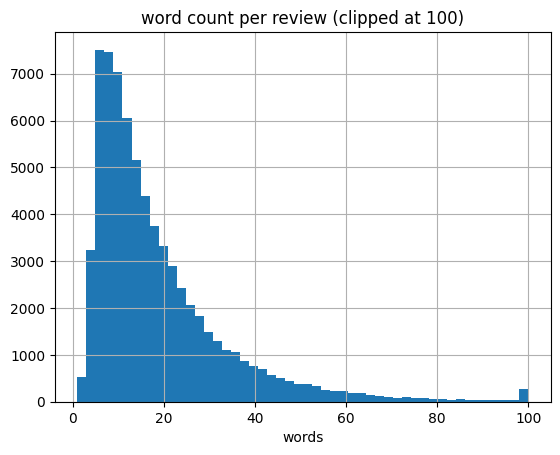

In [7]:
df['n_words'] = df[TEXT_COL].astype(str).str.split().str.len()
print(df['n_words'].describe())

import matplotlib.pyplot as plt
df['n_words'].clip(upper=100).hist(bins=50)
plt.title('word count per review (clipped at 100)'); plt.xlabel('words'); plt.show()

## قدم ۶: چند نمونه‌ی واقعی بخون
به چشم خودت بخون. دیدن داده مهم‌ترین کار تحلیل‌گره.

In [8]:
pd.set_option('display.max_colwidth', 200)
for lab in df[LABEL_COL].dropna().unique():
    print('=====', lab)
    print(df[df[LABEL_COL] == lab][TEXT_COL].sample(5, random_state=1).to_string(index=False))

===== SAD
                                                                                                     تو قیمتا زده بود پیتزا ۴ فصل و ۳۶۷۰۰ با ۲ تا نوشابه که میشه اونم ۵ میشه ۴۱۷۰۰ ولی از من ۴۸۷۰۰ گرفتن
                                                                                                                                                      اصلا" راضى نبودم ١ساعت و نیم طول کشید به دستم برسه
                            اصلا راضی نیستم با این که اولین بار نبود که به سیب سفارش میدادم اما اخرین بار خواهد بود. متاسفانه سفارشم با دو ساعت تاخیر به دستم رسید غذا هم کیفیت همیشگی را نداشت متاسفانه
                                                                                                               مرغ تریاکی اصلا مزه سس تریاکی نمیداد. ولی یه سس سفید رنگ داشت که مزه مایونز با روغن میداد
متاسفانه علارقم زحمت زیادی که برای پخت پیتزا کشیده شده بودند. همونطور که یک نفر دیگه هم در مورد پیتزا الفردو گفته بودند متاسفانه مرغ‌ها با حجم زیاد رو پیتزا ریخته شده ولی ظاهرا این مرغ ف

## قدم ۷: ذخیره‌ی خام روی دیسک موقت Colab
این پوشه با بسته شدن Colab پاک می‌شه و اشکالی نداره، چون با اجرای دوباره‌ی نوت‌بوک ساخته می‌شه. بعداً داده‌ی پاک‌شده‌ی کوچک رو توی GitHub می‌ذاریم.

In [9]:
os.makedirs('/content/cx-radar/data/raw', exist_ok=True)
df.to_parquet('/content/cx-radar/data/raw/snappfood_raw.parquet', index=False)
print('ذخیره شد، حجم:', os.path.getsize('/content/cx-radar/data/raw/snappfood_raw.parquet')//1024, 'KB')

ذخیره شد، حجم: 5554 KB


## ✍️ تمرین (جواب‌ها رو برای من بفرست)
۱. چند ردیف داریم و چند تا تکراریه؟
۲. توزیع برچسب‌ها متعادله؟
۳. میانگین و بیشترین طول نظرها چقدره؟
۴. توی ۱۰ نمونه‌ای که خوندی، چه چیزهای «کثیفی» دیدی؟ (ایموجی، فینگلیش، غلط املایی، ...)

In [10]:
bad = df[df['label'].astype(str).isin(['0', '1'])]
print('تعداد ردیف خراب:', len(bad))
print(bad['source_file'].value_counts())
print(list(df.columns))
bad.head(10)

تعداد ردیف خراب: 520
source_file
Snappfood - Sentiment Analysis.csv    520
Name: count, dtype: int64
['Unnamed: 0', 'comment', 'label', 'label_id', 'source_file', 'n_words']


,Unnamed: 0,comment,label,label_id,source_file,n_words
21,هزار پول ساندویچ شد، ولی بیشترش قارچ بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
89,ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ! و تحویل ساندویخ سرد و خیس!,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
161,تومن پیتزا خریدم سس نداده بود بدون سس خوردم,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
180,تا شونه تخم مرغ را نیاوردید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
243,- سریع رسید ۲- بسته بندی مناسب بود ۳- دور چین خوراک کباب لقمه ضعیف بود، برای سه پرس غذا فقط یک برش پیاز، یک بسته سبزی و دو عدد فلفل کوچیک و یه اسلایس کوچک ته دیگ … همین!!,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
287,تا سنگگ یک ساعت و بیست دقیقه باید طول بکشه؟!!! غذا تموم شد نیم ساعت بعد سنگگ‌ رسید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
288,عدد بستنی داخل سفارشم بود اما ارسال نشد حتی داخل فاکتور هم تیک نخورده اگر نداشتن باید اطلاع میدادن ممنون,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
415,ساعت ۳۰ دقیقه طول کشید تا آورد اصلا وقت مردم مهم نیست براتون,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
480,ساعت طول کشید تا برسه.. ‌ جلو مهمونا آبروم رفت,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
507,تیکه فیله اندازه سه بند انگشت. واقعات جالب بود. مگه میشه آخه. من از همه رستورانهای محدوده خرید کردم. ولی امروز شاخ درآوردم. کیفیت خوب بود ولی واقعا حجم غذا خیلی کم بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1


In [11]:
df_clean = df[df['label'].isin(['HAPPY', 'SAD'])].copy()
print('بعد از حذف ردیف‌های خراب:', len(df_clean))

# 1 یعنی منفی (SAD)، چون هدف ما پیدا کردن شکایت‌هاست
df_clean['is_negative'] = (df_clean['label'] == 'SAD').astype(int)

بعد از حذف ردیف‌های خراب: 69480


In [12]:
import re
from hazm import Normalizer

normalizer = Normalizer()
digit_map = str.maketrans('۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩', '01234567890123456789')

def clean_text(t):
    t = str(t)
    t = t.replace('ي', 'ی').replace('ى', 'ی').replace('ك', 'ک')   # حروف عربی
    t = normalizer.normalize(t)                                    # فاصله، کشیده، ...
    t = t.translate(digit_map)                                     # همه‌ی رقم‌ها انگلیسی
    t = re.sub(r'https?://\S+', ' ', t)                            # لینک
    t = re.sub(r'([^\W\d_])\1{2,}', r'\1\1', t)                    # خیلییییی → خیلیی
    t = re.sub(r'(\d)([^\W\d_])', r'\1 \2', t)                     # 1ساعت → 1 ساعت
    t = re.sub(r'([^\W\d_])(\d)', r'\1 \2', t)                     # پیتزا4 → پیتزا 4
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df_clean['text'] = df_clean['comment'].map(clean_text)

for i in df_clean.sample(5, random_state=3).index:
    print('قبل :', df_clean.loc[i, 'comment'])
    print('بعد :', df_clean.loc[i, 'text'])
    print()

قبل : خیلی مزخرف بود سالاد شیرازی که خیار نداشت تو یه کیسه‌ای پیچونده بودن که چرب بود کباب ش هم لاستیک متاسفم
بعد : خیلی مزخرف بود سالاد شیرازی که خیار نداشت تو یه کیسه‌ای پیچونده بودن که چرب بود کباب‌ش هم لاستیک متاسفم

قبل : در کل حجم و طعم خوبی داشت اما خیلی شور بود
بعد : در کل حجم و طعم خوبی داشت اما خیلی شور بود

قبل : متاسفانه غذا بسیار بی کیفیت (چرب و غرق در روغن فراوان و آبکی و رقیق) بود. امیدوارم نسبت به بالابردن کیفیت تجدید نظر شود.
بعد : متاسفانه غذا بسیار بی‌کیفیت (چرب و غرق در روغن فراوان و آبکی و رقیق) بود. امیدوارم نسبت به بالابردن کیفیت تجدید نظر شود.

قبل : سپاس. از شما مامان و بابام دوست داشتن واین رضایت ارزشمند بود.
بعد : سپاس. از شما مامان و بابام دوست داشتن واین رضایت ارزشمند بود.

قبل : پیتزا بسیار با کیفیت و خوشمزه در بسته بندی زیبا
بعد : پیتزا بسیار با کیفیت و خوشمزه در بسته بندی زیبا



In [13]:
df_clean = df_clean[df_clean['text'].str.len() > 0]

print('تکراری واقعی:', df_clean.duplicated('text').sum())

# یک متن که یک بار HAPPY و یک بار SAD خورده
conf = df_clean.groupby('text')['is_negative'].nunique()
conf = conf[conf > 1]
print('متن یکسان با برچسب متناقض:', len(conf))
print(conf.index[:5].tolist())

تکراری واقعی: 55
متن یکسان با برچسب متناقض: 4
['خوشمزه بود ولی حجمش خیلی کم بود', 'سالاد کلم خیلی کوچیک بود', 'شیرینی تازه نبود اصلا', 'مرغ بوی زخم می\u200cداد']


In [14]:
df_clean = df_clean[~df_clean['text'].isin(conf.index)]
df_clean = df_clean.drop_duplicates('text')
df_clean['n_words'] = df_clean['text'].str.split().str.len()

print('ردیف نهایی:', len(df_clean))
print(df_clean['is_negative'].value_counts(normalize=True).round(3))
print('نظرهای ۲ کلمه‌ای یا کمتر:', (df_clean['n_words'] <= 2).sum())

os.makedirs('/content/cx-radar/data/interim', exist_ok=True)
df_clean[['text', 'is_negative', 'n_words']].to_parquet(
    '/content/cx-radar/data/interim/snappfood_clean.parquet', index=False)

ردیف نهایی: 69421
is_negative
0    0.502
1    0.498
Name: proportion, dtype: float64
نظرهای ۲ کلمه‌ای یا کمتر: 2
